# Importação de Bibliotecas

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
#import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
import joblib

In [2]:
# Configuração visual para os gráficos
plt.rcParams['figure.figsize'] = (14, 7)

# Ingestão e inspeção dos dados

In [14]:
acao_analisada = 'NTDOY' #Caso haja um novo arquivo, só mudar o nome aqui

In [15]:
# Lendo o CSV gerado pelo arquivo obter_dados.py
caminho_arquivo = f'../data/dados_historicos_{acao_analisada}.csv'
df = pd.read_csv(caminho_arquivo)

# Convertendo a coluna Date para o tipo datetime do Pandas, e ordenando
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Confirmando que base não tem nulos
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 3598 entries, 0 to 3597
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    3598 non-null   datetime64[us]
 1   Close   3598 non-null   float64       
 2   High    3598 non-null   float64       
 3   Low     3598 non-null   float64       
 4   Open    3598 non-null   float64       
 5   Volume  3598 non-null   int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 168.8 KB
None


# Visualização da variável target

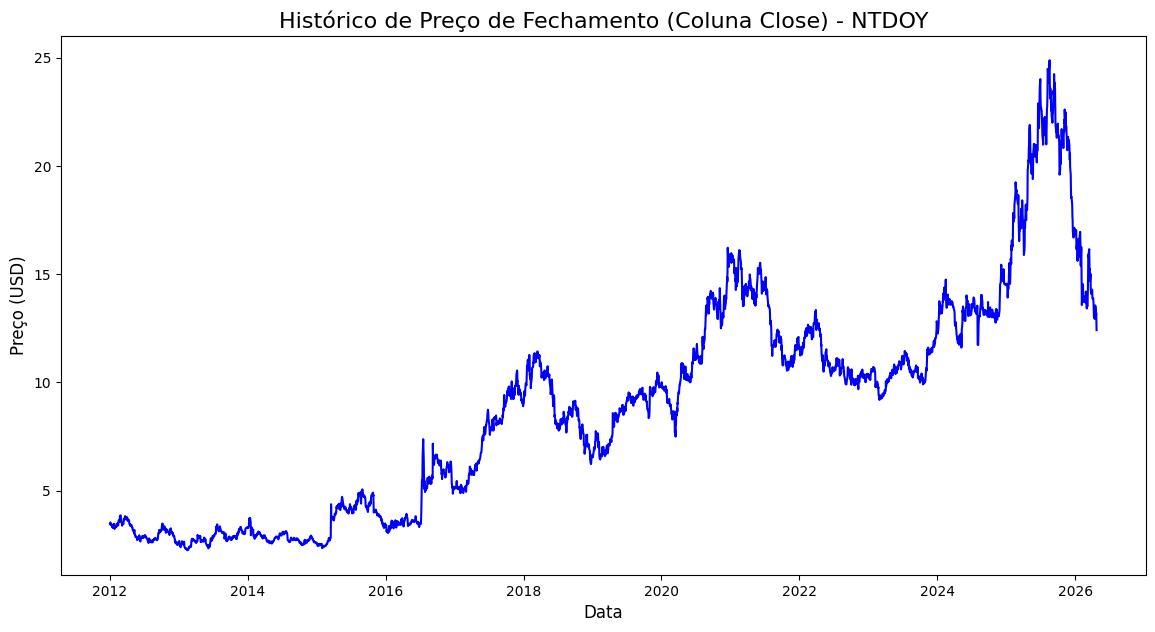

In [16]:
plt.plot(df['Date'], df['Close'], color='blue', linewidth=1.5)
plt.title(f'Histórico de Preço de Fechamento (Coluna Close) - {acao_analisada}', fontsize=16)
plt.xlabel('Data', fontsize=12)
plt.ylabel('Preço (USD)', fontsize=12)
plt.show()

# Separação e normalização

In [17]:
# Isolando a variável alvo (Close) como um array numpy
dataset = df[['Close']].values

# Divisão em Treino e Teste (80/20), respeitando a ordem cronológica (não pegando 80/20 aleatoriamente)
treino_tamanho = int(len(dataset) * 0.8)
dados_treino = dataset[:treino_tamanho]
dados_teste = dataset[treino_tamanho:]

# Normalização (0 a 1)
scaler = MinMaxScaler(feature_range=(0, 1))

# Fit e transform nos dados de treino
dados_treino_scaled = scaler.fit_transform(dados_treino)

# Apenas transform nos dados de teste para não recalcular o minimo e maximo
dados_teste_scaled = scaler.transform(dados_teste)

print(f"Tamanho do Treino: {len(dados_treino)}")
print(f"Tamanho do Teste: {len(dados_teste)}")

Tamanho do Treino: 2878
Tamanho do Teste: 720


# Criação do Tensor de 3 dimensões

In [18]:
def criar_sequencias(dados, passos_tempo=60):
    """
    Cria os vetores X (features) e y (target) baseados em uma janela de tempo.
    """
    X, y = [], []
    for i in range(passos_tempo, len(dados)):
        X.append(dados[i-passos_tempo:i, 0])
        y.append(dados[i, 0])
    return np.array(X), np.array(y)

# Definindo a janela de 60 dias
passos_tempo = 60 

# Construindo as sequências
X_treino, y_treino = criar_sequencias(dados_treino_scaled, passos_tempo)
X_teste, y_teste = criar_sequencias(dados_teste_scaled, passos_tempo)

# Reshape para o tres dimensões exigido pelo LSTM: (amostras, passos_de_tempo, features)
# Como estamos usando apenas a coluna 'Close', temos 1 feature.
X_treino = np.reshape(X_treino, (X_treino.shape[0], X_treino.shape[1], 1))
X_teste = np.reshape(X_teste, (X_teste.shape[0], X_teste.shape[1], 1))

print(f"Formato de X_treino (Tensor 3 dimensões): {X_treino.shape}")
print(f"Formato de y_treino (Vetor Alvo): {y_treino.shape}")
print(f"Formato de X_teste (Tensor 3 dimensões): {X_teste.shape}")

Formato de X_treino (Tensor 3 dimensões): (2818, 60, 1)
Formato de y_treino (Vetor Alvo): (2818,)
Formato de X_teste (Tensor 3 dimensões): (660, 60, 1)


# Construcao Arquitetura LSTM

In [19]:
# Inicializando a rede neural sequencial, já que nossa abordagem é simples / linear
modelo_lstm = Sequential()

# Prepara receber pacotes de 60 dias para prever o próximo, com uma feature
modelo_lstm.add(Input(shape=(X_treino.shape[1], 1)))

# Define primeira camada LSTM com 50 neuronios e 20% de Dropout para evitar overfitting
modelo_lstm.add(LSTM(units=50, return_sequences=True))
modelo_lstm.add(Dropout(0.2))

# 2ª Camada LSTM e mesmo Dropout
modelo_lstm.add(LSTM(units=50, return_sequences=False))
modelo_lstm.add(Dropout(0.2))

# Camada Densa intermediária para consolidar o aprendizado
modelo_lstm.add(Dense(units=25))

# Camada Densa que consolida a saída
modelo_lstm.add(Dense(units=1))

# Compilando o modelo
# Usado "adam" baseado no problema de ações, para evitar falsos resultados e garantir que o modelo LSTM encontre o menor erro possível mais rápido
# Usado "mean_squared_error" porque é um problema de regressão, e queremos penalizar mais os erros maiores (previsões muito distantes do valor real) 
modelo_lstm.compile(optimizer='adam', loss='mean_squared_error')

# Exibindo o resumo da arquitetura
modelo_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

# Treinamento do Modelo

In [20]:
# Definindo os hiperparâmetros de treino

# Escolha de 32 para o lote: multiplo base 2 grande o suficiente para o modelo entender a direção certa a seguir, 
# e pequeno o suficiente para não sobrecarregar a memória da máquina.

#Escolha de 20 epocas: mesma logica anterior, validado pela curva de Loss abaixo 

epocas = 20
tamanho_lote = 32 # O modelo processa 32 janelas por vez antes de atualizar os pesos

print("Iniciando o treinamento da rede LSTM...")

# O history vai guardar os logs de erro para ser exibido depois
history = modelo_lstm.fit(
    X_treino, y_treino,
    batch_size=tamanho_lote,
    epochs=epocas,
    validation_data=(X_teste, y_teste), # Usa o teste para monitorar a generalização
    verbose=1
)

print("\nTreinamento concluído com sucesso!")

Iniciando o treinamento da rede LSTM...
Epoch 1/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.0123 - val_loss: 0.0057
Epoch 2/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0024 - val_loss: 0.0062
Epoch 3/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0020 - val_loss: 0.0069
Epoch 4/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0018 - val_loss: 0.0039
Epoch 5/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0018 - val_loss: 0.0039
Epoch 6/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0015 - val_loss: 0.0041
Epoch 7/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0014 - val_loss: 0.0047
Epoch 8/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0015 - val_loss: 0.0043
Epoch 9/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0013 - val_loss: 0.0075
Epoch 10/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0014 - val_loss: 0.0043
Epoch 11/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0011 - val_loss: 0.0033
Epoch 12/20
89/89 ━━━━━

# Avaliação do Treinamento (Curva de Loss)

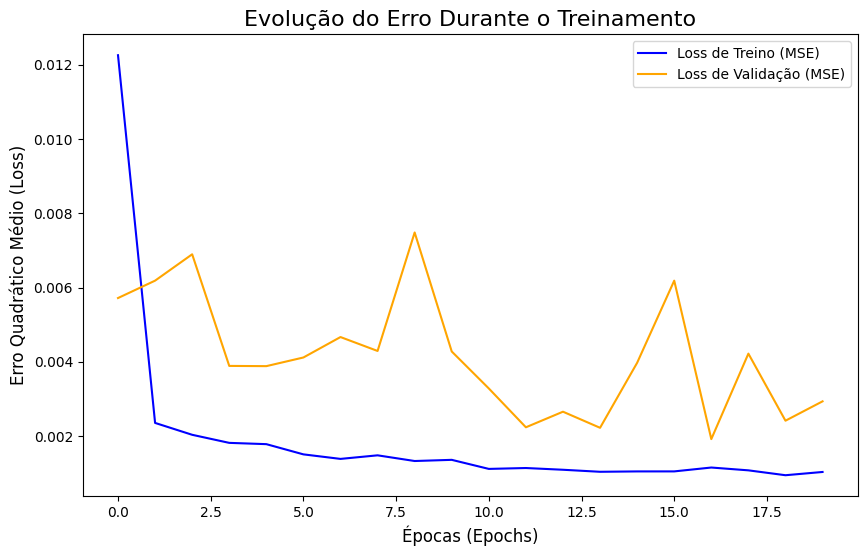

In [21]:
# Plotando a curva de perda (loss) de treino e validação
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Loss de Treino (MSE)', color='blue')
plt.plot(history.history['val_loss'], label='Loss de Validação (MSE)', color='orange')
plt.title('Evolução do Erro Durante o Treinamento', fontsize=16)
plt.xlabel('Épocas (Epochs)', fontsize=12)
plt.ylabel('Erro Quadrático Médio (Loss)', fontsize=12)
plt.legend()
plt.show()

# Previsão e Desnormalização

In [22]:
# Fazendo as previsões com os dados de teste invisíveis ao modelo durante o treino
previsoes_scaled = modelo_lstm.predict(X_teste)

# Invertendo a normalização para voltar ao valor real em Dólares
previsoes_desnormalizadas = scaler.inverse_transform(previsoes_scaled)
y_teste_desnormalizado = scaler.inverse_transform(y_teste.reshape(-1, 1))
previsoes_scaled = modelo_lstm.predict(X_teste)
previsoes_desnormalizadas = scaler.inverse_transform(previsoes_scaled)
y_teste_desnormalizado = scaler.inverse_transform(y_teste.reshape(-1, 1))
print("Previsões realizadas e escalas revertidas com sucesso!")

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Previsões realizadas e escalas revertidas com sucesso!


# Cálculo das métricas e gráfico final do desempenho

--- RESULTADOS DA AVALIAÇÃO DO MODELO LSTM ---
MAE  (Erro Absoluto Médio): $0.55
RMSE (Raiz do Erro Quadrático): $0.76
MAPE (Erro Percentual Médio): 3.24%



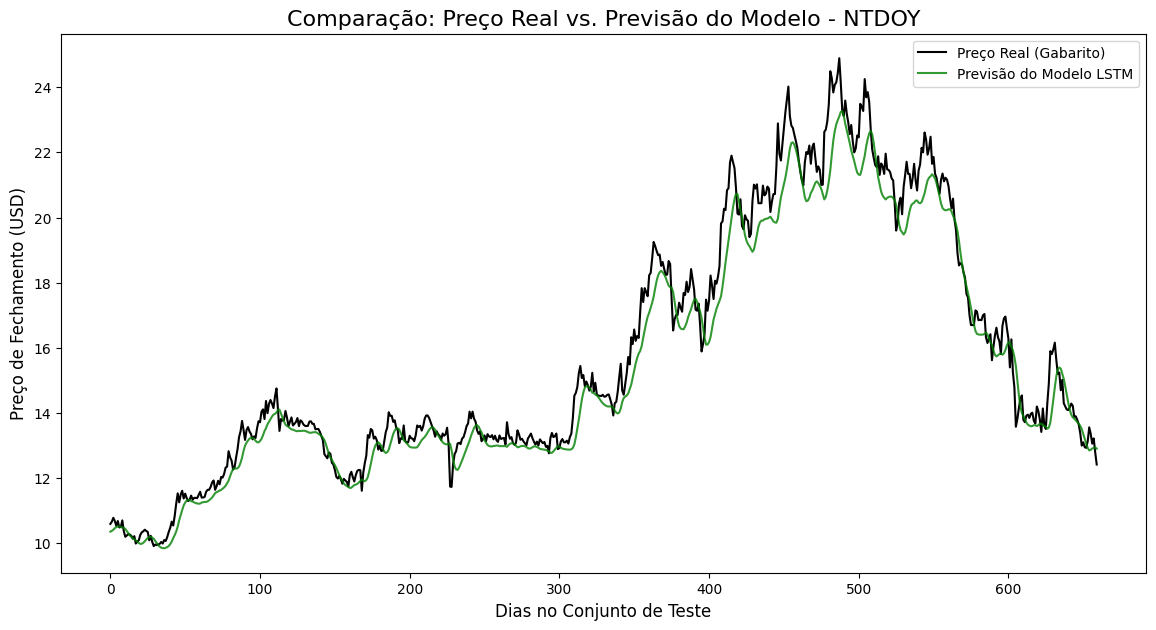

In [23]:
# 1. MAE (Mean Absolute Error): Erro médio absoluto
mae = mean_absolute_error(y_teste_desnormalizado, previsoes_desnormalizadas)

# 2. RMSE (Root Mean Square Error): Penaliza erros maiores
rmse = np.sqrt(mean_squared_error(y_teste_desnormalizado, previsoes_desnormalizadas))

# 3. MAPE (Erro Percentual Absoluto Médio): Qual a margem de erro em %?
def calc_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

mape = calc_mape(y_teste_desnormalizado, previsoes_desnormalizadas)

#Imprimindo os resultados de avaliação e coloando os valores em dólares e/ou percentual
print("--- RESULTADOS DA AVALIAÇÃO DO MODELO LSTM ---")
print(f"MAE  (Erro Absoluto Médio): ${mae:.2f}")
print(f"RMSE (Raiz do Erro Quadrático): ${rmse:.2f}")
print(f"MAPE (Erro Percentual Médio): {mape:.2f}%\n")

# Gráfico de Real vs. Previsto
plt.figure(figsize=(14, 7))
plt.plot(y_teste_desnormalizado, color='black', label='Preço Real (Gabarito)', linewidth=1.5)
plt.plot(previsoes_desnormalizadas, color='green', label='Previsão do Modelo LSTM', linewidth=1.5, alpha=0.8)
plt.title(f'Comparação: Preço Real vs. Previsão do Modelo - {acao_analisada}', fontsize=16)
plt.xlabel('Dias no Conjunto de Teste', fontsize=12)
plt.ylabel('Preço de Fechamento (USD)', fontsize=12)
plt.legend()
plt.show()

# Exportação do Modelo

In [24]:
# Definindo caminho da pasta model e nome do arquivo final
caminho_modelo = f'../model/modelo_{acao_analisada}.keras'
os.makedirs('../model', exist_ok=True)

# Salva o modelo LSTM
modelo_lstm.save(caminho_modelo)

print(f"Modelo LSTM salvo com sucesso em: {caminho_modelo}")

Modelo LSTM salvo com sucesso em: ../model/modelo_NTDOY.keras


In [27]:
# Salva o objeto MinMaxScaler com os padrões matemáticos aprendidos
caminho_scaler = f'../model/scaler_{acao_analisada}.save'
os.makedirs('../model', exist_ok=True)

joblib.dump(scaler, caminho_scaler)

print(f"Scaler salvo com sucesso em: {caminho_scaler}")

Scaler salvo com sucesso em: ../model/scaler_NTDOY.save
